# Combined A–C · Majority and TF-IDF logistic regression

279 training cases (2010–2020), 42 shared development evaluation cases (2021–2022). A retains team-reviewed status; B/C use explicit provisional assumptions. Reserved test cases are not evaluated. This notebook reads and verifies the saved run without refitting models.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Image
RUN = Path('.')
read = lambda n: json.loads((RUN / n).read_text())
run = read('run.json')
results = pd.read_csv(RUN/'results.csv')
display(run['assumptions'])
display(pd.read_csv(RUN/'batch_class_counts.csv'))
display(pd.read_csv(RUN/'class_counts.csv').fillna(''))

{'version': 'abc_provisional_assumptions_v1',
 'recorded_date': '2026-11-18',
 'scope': 'Prepare combined A-C data for provisional development experiments; do not run models yet.',
 'A': {'basis': 'Existing team-reviewed MVP package',
  'review_confirmation': 'experiments/mvp_a/team_review_confirmation.json',
  'promote_source_status': False},
 'B': {'basis': 'Prior explicit user assumption for Batch B',
  'user_instruction': 'Proceed, assuming the labels have been reviewed',
  'label_policy': 'Use the supplied draft_label_if_unanimous_include field for prepared development cases.',
  'source_status': 'pending_human_review',
  'promote_source_status': False},
 'C': {'basis': 'Explicit user authorization for a provisional run',
  'user_instruction': 'Record an explicit provisional-run assumption for batch C and combine all three datasets for A-C',
  'label_policy': 'Use a binary label only when all three saved reviewers agree for a case in the prepared C development package; stop on dis

,batch,split,label_0,label_1,n
0,A,train,59,27,86
1,A,validation,8,8,16
2,B,train,64,33,97
3,B,validation,12,3,15
4,C,train,58,38,96
5,C,validation,5,6,11
6,ALL,train,181,98,279
7,ALL,validation,25,17,42


,scope,fold,n,label_0,label_1
0,train,,279,181,98
1,validation,,42,25,17
2,cv_training,1.0,185,120,65
3,cv_held_out,1.0,94,61,33
4,cv_training,2.0,186,121,65
5,cv_held_out,2.0,93,60,33
6,cv_training,3.0,187,121,66
7,cv_held_out,3.0,92,60,32


## MASKED training selection

Word unigrams/bigrams, min_df=2, max_features=30000, L2-normalized TF-IDF; L2 logistic regression with balanced training-class weights. Each fold fits a fresh pipeline. Three family-grouped folds select C by mean balanced accuracy, then macro F1, then smaller C. The selected C is fixed for separate FULL and MASKED fits.

In [2]:
selection = read('selection.json')['TFIDF_LR']
display(pd.DataFrame([{k:t[k] for k in ['C','balanced_accuracy','macro_f1']} for t in selection['grid']]))
print('Selected C:',selection['selected_C'])
display(run['models']['TFIDF_LR'])

,C,balanced_accuracy,macro_f1
0,0.1,0.623115,0.607339
1,1.0,0.589274,0.589280
2,10.0,0.627153,0.630102


Selected C: 10.0


{'tfidfvectorizer': {'analyzer': 'word',
  'binary': False,
  'decode_error': 'strict',
  'dtype': 'float64',
  'encoding': 'utf-8',
  'input': 'content',
  'lowercase': True,
  'max_df': 1.0,
  'max_features': 30000,
  'min_df': 2,
  'ngram_range': [1, 2],
  'norm': 'l2',
  'preprocessor': None,
  'smooth_idf': True,
  'stop_words': None,
  'strip_accents': None,
  'sublinear_tf': False,
  'token_pattern': '(?u)\\b\\w\\w+\\b',
  'tokenizer': None,
  'use_idf': True,
  'vocabulary': None},
 'logisticregression': {'C': 10.0,
  'class_weight': 'balanced',
  'dual': False,
  'fit_intercept': True,
  'intercept_scaling': 1,
  'l1_ratio': None,
  'max_iter': 10000,
  'multi_class': 'deprecated',
  'n_jobs': None,
  'penalty': 'l2',
  'random_state': 20261023,
  'solver': 'liblinear',
  'tol': 0.0001,
  'verbose': 0,
  'warm_start': False}}

## Development results

Accuracy is the overall correct fraction. Balanced accuracy is mean recall across labels 0 and 1. Macro F1 is mean F1 across both labels. Matrices show raw counts and row-normalized percentages; true rows, predicted columns, order 0, 1.

,model,variant,C,n,accuracy,balanced_accuracy,macro_f1,recall_0,recall_1
0,Majority,FULL,NaN,42,0.595238,0.500000,0.373134,1.00,0.000000
1,Majority,MASKED,NaN,42,0.595238,0.500000,0.373134,1.00,0.000000
2,TFIDF_LR,FULL,10.0,42,0.809524,0.821176,0.807780,0.76,0.882353
3,TFIDF_LR,MASKED,10.0,42,0.571429,0.536471,0.533333,0.72,0.352941


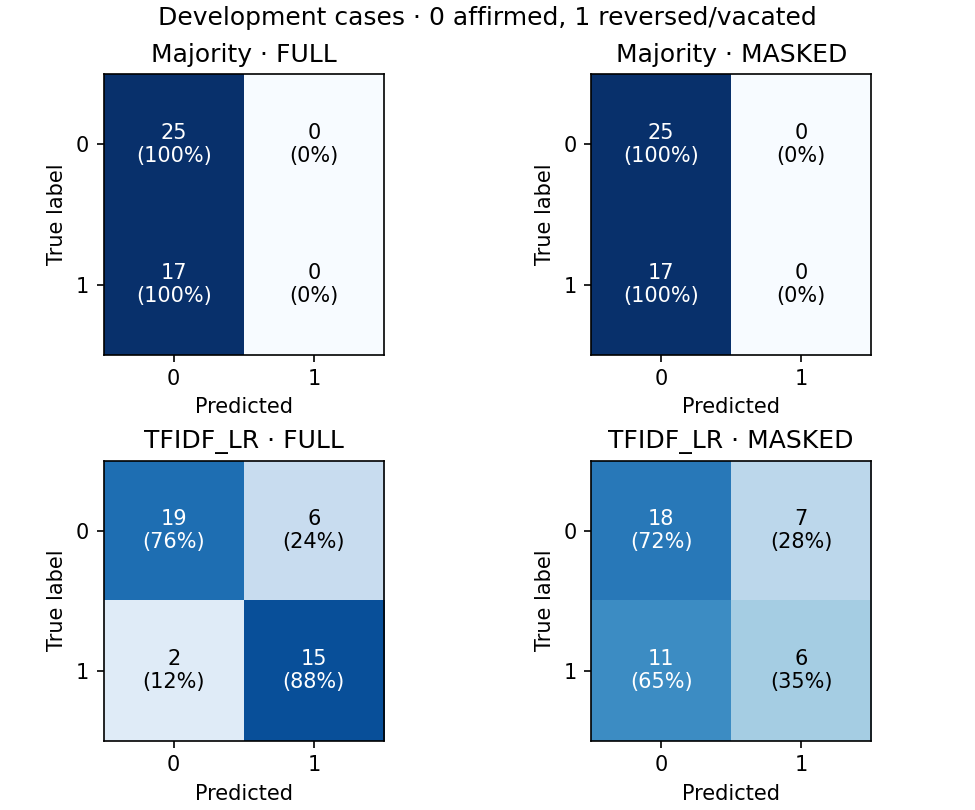

Majority FULL


Predicted,0,1
True,,
0,1.0,0.0
1,1.0,0.0


Majority MASKED


Predicted,0,1
True,,
0,1.0,0.0
1,1.0,0.0


TFIDF_LR FULL


Predicted,0,1
True,,
0,0.760000,0.240000
1,0.117647,0.882353


TFIDF_LR MASKED


Predicted,0,1
True,,
0,0.720000,0.280000
1,0.647059,0.352941


In [3]:
display(results)
display(Image(filename=str(RUN/'confusion_matrices.png')))
for condition in read('reporting_summary.json')['conditions']:
    print(condition['model'],condition['variant'])
    display(pd.DataFrame(condition['row_normalized'],index=pd.Index([0,1],name='True'),columns=pd.Index([0,1],name='Predicted')))

## Independent verification

Recompute metrics from per-case predictions, check shared evaluation IDs, family separation, majority label, fixed C, and report checksums.

In [4]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
pred = pd.read_csv(RUN/'predictions.csv')
splits = pd.read_csv(RUN/'splits.csv')
expected = splits[splits.period=='validation'].set_index('case_id')['label'].to_dict()
training = splits[splits.period=='train']
assert len(expected)==42 and len(training)==279 and len(pred)==168
assert set(training.family_id).isdisjoint(splits[splits.period=='validation'].family_id)
assert training.groupby('family_id').held_out_cv_fold.nunique().max()==1
majority = training.label.value_counts().idxmax()
assert (pred[pred.model=='Majority'].prediction==majority).all()
assert set(pred[pred.model=='TFIDF_LR'].C)=={selection['selected_C']}
for _, result in results.iterrows():
    p=pred[(pred.model==result.model)&(pred.variant==result.variant)]
    assert len(p)==len(expected) and p.set_index('case_id')['label'].to_dict()==expected
    cm=confusion_matrix(p.label,p.prediction,labels=[0,1])
    values={'accuracy':accuracy_score(p.label,p.prediction),'balanced_accuracy':balanced_accuracy_score(p.label,p.prediction),'macro_f1':f1_score(p.label,p.prediction,labels=[0,1],average='macro'),'recall_0':cm[0,0]/cm[0].sum(),'recall_1':cm[1,1]/cm[1].sum()}
    for key,value in values.items():
        assert np.isclose(result[key],value,rtol=0,atol=1e-12)
    stored=next(x for x in read('reporting_summary.json')['conditions'] if x['model']==result.model and x['variant']==result.variant)
    assert stored['counts']==cm.tolist()
    assert np.allclose(stored['row_normalized'],cm/cm.sum(axis=1,keepdims=True))
for name,checksum in read('reporting_summary.json')['source_sha256'].items():
    assert hashlib.sha256((RUN/name).read_bytes()).hexdigest()==checksum
print('Verified all four conditions on identical evaluation cases; original failures remain in the saved predictions.')

Verified all four conditions on identical evaluation cases; original failures remain in the saved predictions.


## Interpretation and reproducibility

The FULL/MASKED contrast is a development comparison of separately fitted pipelines at fixed C. Retained outcome-related reasoning, different upstream masks by batch, prior A/B development exposure, small evaluation size and provisional B/C labels limit interpretation. See REPORT.md for the reproduction command and REPORTING.md for all counts. Select the installed environment’s Python kernel to rerun this notebook.

In [5]:
display(run['software'])
display(read('verification.json'))

{'numpy': '2.3.4',
 'scipy': '1.16.3',
 'scikit-learn': '1.7.2',
 'matplotlib': '3.10.7',
 'torch': '2.9.1',
 'transformers': '4.57.1',
 'tokenizers': '0.22.2',
 'huggingface-hub': '0.36.2',
 'pandas': '2.3.3',
 'nbformat': '5.10.4',
 'nbclient': '0.10.2',
 'ipykernel': '6.30.1'}

{'same_evaluation_cases_and_labels': True,
 'majority_from_training_only': True,
 'family_disjoint_folds': True,
 'each_training_case_held_out_once': True,
 'both_classes_in_each_fold': True,
 'masked_only_selection': True,
 'same_C_for_FULL_MASKED': True,
 'metrics_recomputed_from_saved_predictions': True,
 'input_hashes_unchanged': True,
 'convergence_warnings': 0,
 'reserved_test_evaluated': False,
 'training_cases': 279,
 'evaluation_cases': 42,
 'conditions': 4,
 'training_only_transform_basis': 'Fresh sklearn Pipeline fitted only on each training subset; guarded by synthetic held-out-vocabulary test.'}